In [1]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from collections import deque
import random
import matplotlib.pyplot as plt

In [2]:

class SlipperyCubeEnv:
    def __init__(self):
        self.dt = 0.05
        self.m = 2.0
        self.friction = 0.05

        self.x_limit = 3.0
        self.max_force = 1.0
        self.disturbance_std = 0.15

        self.max_steps = 400 #TODO What does max step correspond to ?
        self.steps = 0
        self.v = 0

    def reset(self):
        self.x = np.random.uniform(-1,1)
        self.v = 0
        self.steps = 0

        return np.array([self.x, self.v], dtype=np.float32)

    def step(self,force):

        force = float(np.clip(np.asarray(force).squeeze(),-self.max_force,self.max_force))
        # generate a Gaussian disturbance
        disturbance_force = np.random.normal(0,self.disturbance_std) # mean of 0N
        acceleration = (force + disturbance_force - self.friction * self.v) / self.m

        # integrate to get position and velocity from acceleration
        self.v += acceleration * self.dt
        self.x += self.v * self.dt

        self.steps += 1

        reward = (
            -self.x**2
            - 0.1 * self.v**2
            - 0.01 * force**2
        )

        fell_off = abs(self.x) >= self.x_limit

        if fell_off:
            reward -= 100
        # so in general the reward will be negative and approach 0 as the policy improves.

        timeout = self.steps >= self.max_steps

        done = fell_off or timeout

        state = np.array(
            [self.x, self.v],
            dtype=np.float32
        )

        return state, float(reward), done



In [3]:
class ReplayBuffer:

    def __init__(self, capacity=100_000):
        self.buffer = deque(maxlen=capacity)

    def add(self, state, action, reward, next_state, done):

        self.buffer.append(
            (
                np.array(state, dtype=np.float32),
                np.array(action, dtype=np.float32),
                float(reward),
                np.array(next_state, dtype=np.float32),
                float(done)
            )
        )

    def sample(self, batch_size):
        # batch size corresponds to the number of transitions you return at a time to update the policy

        batch = random.sample(
            self.buffer,
            batch_size
        )

        states, actions, rewards, next_states, dones = zip(*batch)

        states = torch.tensor(
            np.array(states),
            dtype=torch.float32
        )

        actions = torch.tensor(
            np.array(actions),
            dtype=torch.float32
        )

        # Make sure action shape is [batch_size, 1]
        if actions.ndim == 1:
            actions = actions.unsqueeze(1)

        rewards = torch.tensor(
            rewards,
            dtype=torch.float32
        ).unsqueeze(1)

        next_states = torch.tensor(
            np.array(next_states),
            dtype=torch.float32
        )

        dones = torch.tensor(
            dones,
            dtype=torch.float32
        ).unsqueeze(1)

        return (
            states,
            actions,
            rewards,
            next_states,
            dones
        )

    def __len__(self):
        return len(self.buffer)



The actor represents $$\pi (F |x,v) = \pi (F | \vec{s})$$ where $\vec{s} = \bigl( \begin{smallmatrix} x \\ v \end{smallmatrix} \bigr)$ is the state vector

In [4]:
class Actor(nn.Module):

    def __init__(self,max_action):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(2, 64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU()
        )
        self.max_action = max_action
        self.mu_layer = nn.Linear(64, 1) # this outputs our mu
        self.log_std_layer = nn.Linear(64, 1) # this outputs our std

    # nn.Module provides eval(), forward()

    def forward(self,state):

        hidden = self.network(state) # state vector -> hidden

        mu = self.mu_layer(hidden) # hidden -> mu layer

        log_sigma = self.log_std_layer(hidden) # hidden -> sigma
        # the DNN can output any value including negative values which would be invalid for sigma. So we will take the exponantial of the output to ensure it is positive.

        log_sigma = torch.clamp(log_sigma,-20,2)

        return mu, log_sigma

    def sample(self,state):
        mu, log_sigma = self.forward(state)
        sigma = log_sigma.exp()

        # apply the Gaussian policy :
        distribution = torch.distributions.Normal(mu,sigma)

        #TODO how does reparametrization work here ? It is not central to learning SAC so dont need to understand for now
               # Reparameterization trick:
        #
        # z = mu + sigma * epsilon
        #
        # rsample() allows gradients to propagate
        z = distribution.rsample()

        # Constrain action to [-1, 1]
        tanh_action = torch.tanh(z)

        action = self.max_action * tanh_action

        # ----------------------------------------------------
        # Compute log pi(a | s)
        #
        # Because we pass z through tanh(), we need a
        # change-of-variables correction.
        # ----------------------------------------------------

        log_prob = distribution.log_prob(z)

        log_prob -= torch.log(
            1 - tanh_action.pow(2) + 1e-6
        )

        log_prob = log_prob.sum(
            dim=1,
            keepdim=True
        )

        # Deterministic action for evaluation
        mean_action = (
            self.max_action
            * torch.tanh(mu)
        )

        return action, log_prob, mean_action

The critic will approximate $$Q_\pi(\vec{s},a)$$ and estimates how good it is to apply force F while the cube has state variable s.

In [5]:
class Critic(nn.Module):
    # the critic ESTIMATES Q(s,a) or s is a two dimensional vector so we need 2 + 1 = 3 input features
    def __init__(self):

        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(3,64),
            nn.ReLU(),
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64,1)) # one scalar that corresponds to the estimate of Q(s,a)

    def forward(self, state, action):

        state_action = torch.cat(
            [state, action],
            dim=1
        )

        estimate = self.network(state_action)

        return estimate

In [6]:
class SACAgent:

    def __init__(
        self,
        max_action,
        learning_rate=0.001,
        gamma=0.99,
        alpha=0.2
    ):

        self.learning_rate = learning_rate
        self.gamma = gamma
        self.alpha = alpha

        self.actor = Actor(max_action)

        self.critic1 = Critic()
        self.critic2 = Critic()

        # An optimizer updates the neural-network weights
        # using the gradients computed by backpropagation.
        self.actor_optimizer = optim.Adam(
            self.actor.parameters(),
            lr=self.learning_rate
        )

        self.critic1_optimizer = optim.Adam(
            self.critic1.parameters(),
            lr=self.learning_rate
        )

        self.critic2_optimizer = optim.Adam(
            self.critic2.parameters(),
            lr=self.learning_rate
        )

    def select_action(self, state, deterministic=False):

        state = torch.tensor(
            state,
            dtype=torch.float32
        ).unsqueeze(0)

        with torch.no_grad():
            action, _, mean_action = self.actor.sample(state)

        if deterministic:
            return mean_action.squeeze(0).numpy()

        return action.squeeze(0).numpy()

    def update(self, replay_buffer, batch_size):

        # 1. Sample a batch from replay memory
        states, actions, rewards, next_states, dones = \
            replay_buffer.sample(batch_size)

        # 2. Build the soft TD target
        with torch.no_grad():

            next_actions, next_log_probs, _ = \
                self.actor.sample(next_states)

            q1_next = self.critic1(
                next_states,
                next_actions
            )

            q2_next = self.critic2(
                next_states,
                next_actions
            )

            q_next = torch.min(
                q1_next,
                q2_next
            )

            target_q = (
                rewards
                + self.gamma
                * (1 - dones)
                * (
                    q_next
                    - self.alpha * next_log_probs
                )
            )

        # 3. Update critic 1
        current_q1 = self.critic1(
            states,
            actions
        )

        critic1_loss = nn.functional.mse_loss(
            current_q1,
            target_q
        )

        self.critic1_optimizer.zero_grad()
        critic1_loss.backward()
        self.critic1_optimizer.step()

        # 4. Update critic 2
        current_q2 = self.critic2(
            states,
            actions
        )

        critic2_loss = nn.functional.mse_loss(
            current_q2,
            target_q
        )

        self.critic2_optimizer.zero_grad()
        critic2_loss.backward()
        self.critic2_optimizer.step()

        # 5. Update actor
        new_actions, log_probs, _ = \
            self.actor.sample(states)

        q1_new = self.critic1(
            states,
            new_actions
        )

        q2_new = self.critic2(
            states,
            new_actions
        )

        q_new = torch.min(
            q1_new,
            q2_new
        )

        actor_loss = (
            self.alpha * log_probs
            - q_new
        ).mean()

        self.actor_optimizer.zero_grad()
        actor_loss.backward()
        self.actor_optimizer.step()

        return (
            actor_loss.item(),
            critic1_loss.item(),
            critic2_loss.item()
        )

In [29]:
num_episodes = 10
batch_size = 64
warmup_steps = 1000

total_steps = 0
episode_rewards = []

for episode in range(num_episodes):

    state = env.reset()
    done = False
    episode_reward = 0

    while not done:

        # Random exploration at the beginning
        if total_steps < warmup_steps:
            action = np.array([
                np.random.uniform(
                    -env.max_force,
                    env.max_force
                )
            ])
        else:
            action = agent.select_action(state)

        next_state, reward, done = env.step(action)

        buffer.add(
            state,
            action,
            reward,
            next_state,
            done
        )

        state = next_state
        episode_reward += reward
        total_steps += 1

        # Start learning once enough samples exist
        if len(buffer) >= batch_size:
            actor_loss, q1_loss, q2_loss = agent.update(
                buffer,
                batch_size
            )

    episode_rewards.append(episode_reward)

    if episode % 10 == 0:
        print(
            f"Episode {episode}, "
            f"Reward: {episode_reward:.2f}"
        )

Episode 0, Reward: -1266.80


In [30]:
state = env.reset()
done = False

times = []
positions = []
velocities = []
forces = []
rewards = []

step = 0

while not done:

    action = agent.select_action(
        state,
        deterministic=True
    )

    force = float(np.asarray(action).squeeze())

    times.append(step * env.dt)
    positions.append(state[0])
    velocities.append(state[1])
    forces.append(force)

    next_state, reward, done = env.step(action)
    rewards.append(reward)

    state = next_state
    step += 1

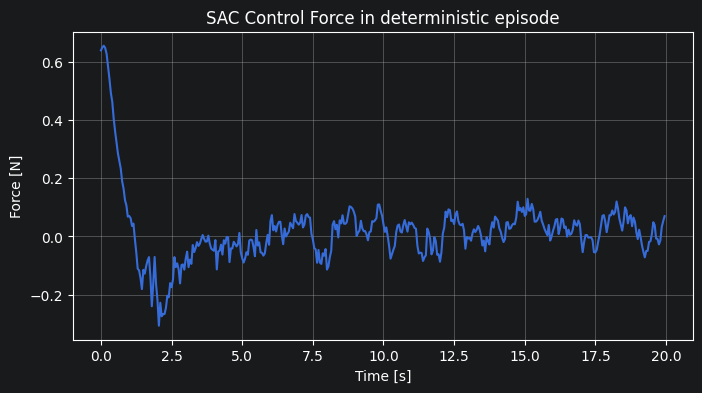

In [31]:
plt.figure(figsize=(8, 4))

plt.plot(times, forces)

plt.xlabel("Time [s]")
plt.ylabel("Force [N]")
plt.title("SAC Control Force in deterministic episode")
plt.grid()

plt.show()

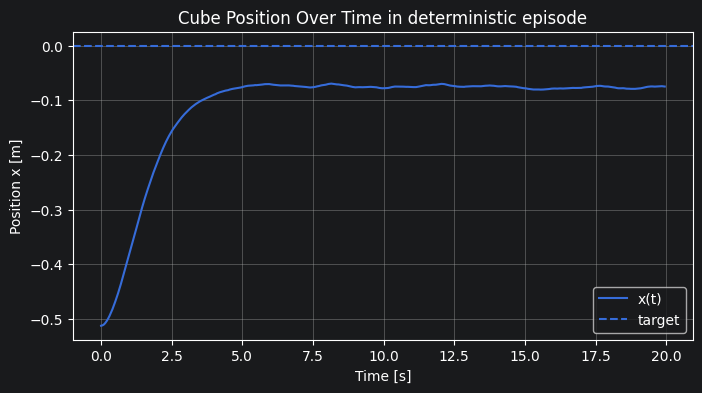

In [32]:
plt.figure(figsize=(8, 4))

plt.plot(times, positions, label="x(t)")
plt.axhline(0, linestyle="--", label="target")

plt.xlabel("Time [s]")
plt.ylabel("Position x [m]")
plt.title("Cube Position Over Time in deterministic episode")
plt.grid()
plt.legend()

plt.show()

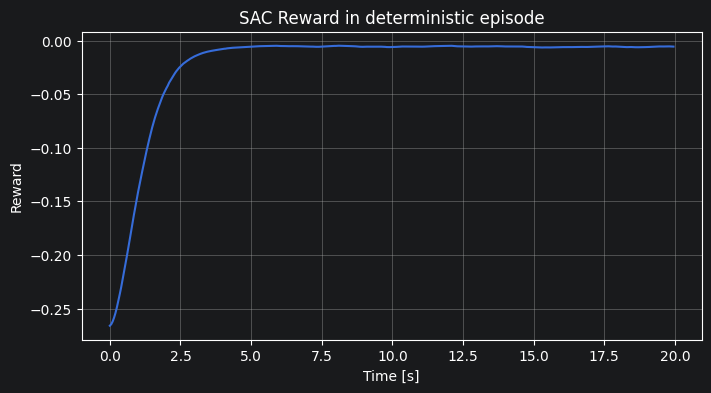

In [33]:
plt.figure(figsize=(8, 4))

plt.plot(times, rewards)

plt.xlabel("Time [s]")
plt.ylabel("Reward")
plt.title("SAC Reward in deterministic episode")
plt.grid()

plt.show()